In [ ]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler, RobustScaler, label_binarize
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
from imblearn.over_sampling import SMOTE, RandomOverSampler


In [ ]:
url = 'https://raw.githubusercontent.com/naufalfrdss/Data_Sains/refs/heads/main/datakotor.csv'
data = pd.read_csv(url)

In [ ]:
data

,Age,Gender,Education,Introversion Score,Sensing Score,Thinking Score,Judging Score,Interest,Personality
0,21.0,Female,1,5.89208,2.144395,7.32363,5.462224,Arts,ENTP
1,24.0,Female,1,2.48366,3.206188,8.06876,3.765012,Unknown,INTP
2,26.0,Female,1,7.02910,6.469302,4.16472,5.454442,Others,ESFP
3,30.0,Male,0,5.46525,4.179244,2.82487,5.080477,Sports,ENFJ
4,31.0,Female,0,3.59804,6.189259,5.31347,3.677984,Others,ISFP
...,...,...,...,...,...,...,...,...,...
43739,26.0,Male,1,8.88656,5.118399,8.48784,5.331942,NaN,ENTP
43740,29.0,Male,0,2.71470,6.851956,0.25519,3.623678,Unknown,ISFP
43741,25.0,Female,0,2.00982,6.544036,6.63911,6.201555,Technology,ISTJ
43742,23.0,Male,0,7.23553,4.876780,2.41671,4.654016,Arts,ENFP


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43744 entries, 0 to 43743
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 43742 non-null  float64
 1   Gender              43742 non-null  object 
 2   Education           43744 non-null  int64  
 3   Introversion Score  43741 non-null  float64
 4   Sensing Score       43741 non-null  float64
 5   Thinking Score      43744 non-null  float64
 6   Judging Score       43740 non-null  float64
 7   Interest            43741 non-null  object 
 8   Personality         43742 non-null  object 
dtypes: float64(5), int64(1), object(3)
memory usage: 3.0+ MB


In [ ]:
data.isnull().sum()

,0
Age,2
Gender,2
Education,0
Introversion Score,3
Sensing Score,3
Thinking Score,0
Judging Score,4
Interest,3
Personality,2


In [ ]:
data.duplicated().sum()

np.int64(1027)

In [ ]:
data.drop_duplicates(inplace=True)

In [ ]:
data['Gender'] = data['Gender'].map({'Male': 0, 'Female': 1})

In [ ]:
data.head()

,Age,Gender,Education,Introversion Score,Sensing Score,Thinking Score,Judging Score,Interest,Personality
0,21.0,1.0,1,5.89208,2.144395,7.32363,5.462224,Arts,ENTP
1,24.0,1.0,1,2.48366,3.206188,8.06876,3.765012,Unknown,INTP
2,26.0,1.0,1,7.02910,6.469302,4.16472,5.454442,Others,ESFP
3,30.0,0.0,0,5.46525,4.179244,2.82487,5.080477,Sports,ENFJ
4,31.0,1.0,0,3.59804,6.189259,5.31347,3.677984,Others,ISFP


In [ ]:
data["Personality"].unique()

array(['ENTP', 'INTP', 'ESFP', 'ENFJ', 'ISFP', 'ISFJ', 'ESTJ', 'INFP',
       'ESTP', 'ENFP', 'INTJ', 'ESFJ', 'ISTJ', 'INFJ', 'ISTP', 'ENTJ',
       nan], dtype=object)

In [ ]:
encoder = LabelEncoder()
data["Personality"] = encoder.fit_transform(data["Personality"])

In [ ]:
data['Interest'].unique()

array(['Arts', 'Unknown', 'Others', 'Sports', 'Technology'], dtype=object)

In [ ]:
data['Interest'] = encoder.fit_transform(data['Interest'])

In [ ]:
data['Interest'].unique()

array([0, 4, 1, 2, 3, 5])

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 42717 entries, 0 to 43743
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 42715 non-null  float64
 1   Gender              42715 non-null  float64
 2   Education           42717 non-null  int64  
 3   Introversion Score  42714 non-null  float64
 4   Sensing Score       42714 non-null  float64
 5   Thinking Score      42717 non-null  float64
 6   Judging Score       42713 non-null  float64
 7   Interest            42717 non-null  int64  
 8   Personality         42717 non-null  int64  
dtypes: float64(6), int64(3)
memory usage: 3.3 MB


In [ ]:
data.dropna(inplace=True)

In [ ]:
data.corr()

,Age,Gender,Education,Introversion Score,Sensing Score,Thinking Score,Judging Score,Interest,Personality
Age,1.000000,-0.004118,0.006525,-0.002161,0.164137,-0.009180,0.000312,0.000188,0.128542
Gender,-0.004118,1.000000,-0.006388,0.007420,-0.000749,0.001619,0.001136,-0.000505,-0.072237
Education,0.006525,-0.006388,1.000000,-0.010457,0.005065,0.015290,-0.301655,0.003193,0.080587
Introversion Score,-0.002161,0.007420,-0.010457,1.000000,0.015768,0.010055,0.019235,-0.001527,-0.721302
Sensing Score,0.164137,-0.000749,0.005065,0.015768,1.000000,-0.005837,-0.010742,0.005157,0.302019
Thinking Score,-0.009180,0.001619,0.015290,0.010055,-0.005837,1.000000,-0.013370,0.006524,0.173096
Judging Score,0.000312,0.001136,-0.301655,0.019235,-0.010742,-0.013370,1.000000,0.002725,-0.104054
Interest,0.000188,-0.000505,0.003193,-0.001527,0.005157,0.006524,0.002725,1.000000,-0.009499
Personality,0.128542,-0.072237,0.080587,-0.721302,0.302019,0.173096,-0.104054,-0.009499,1.000000


<Axes: >

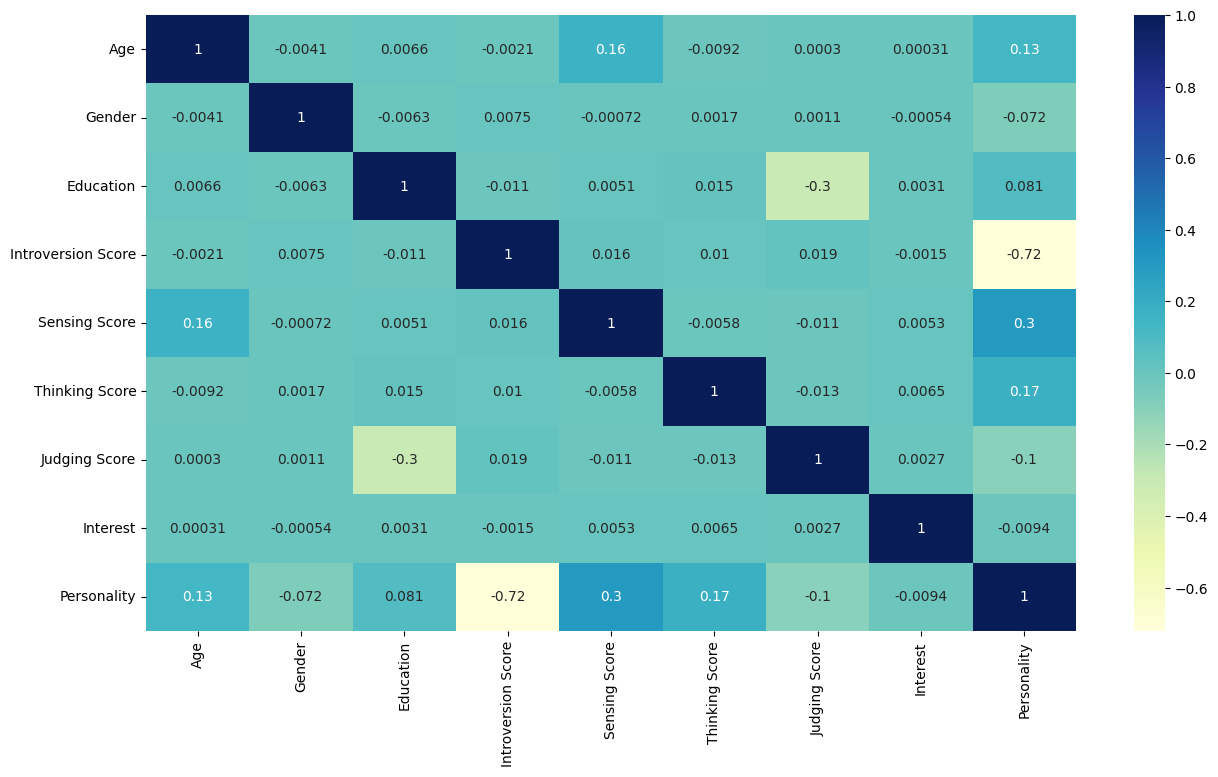

In [ ]:
plt.figure(figsize=(15, 8))
sns.heatmap(data.corr(), annot=True, cmap="YlGnBu")

<Axes: >

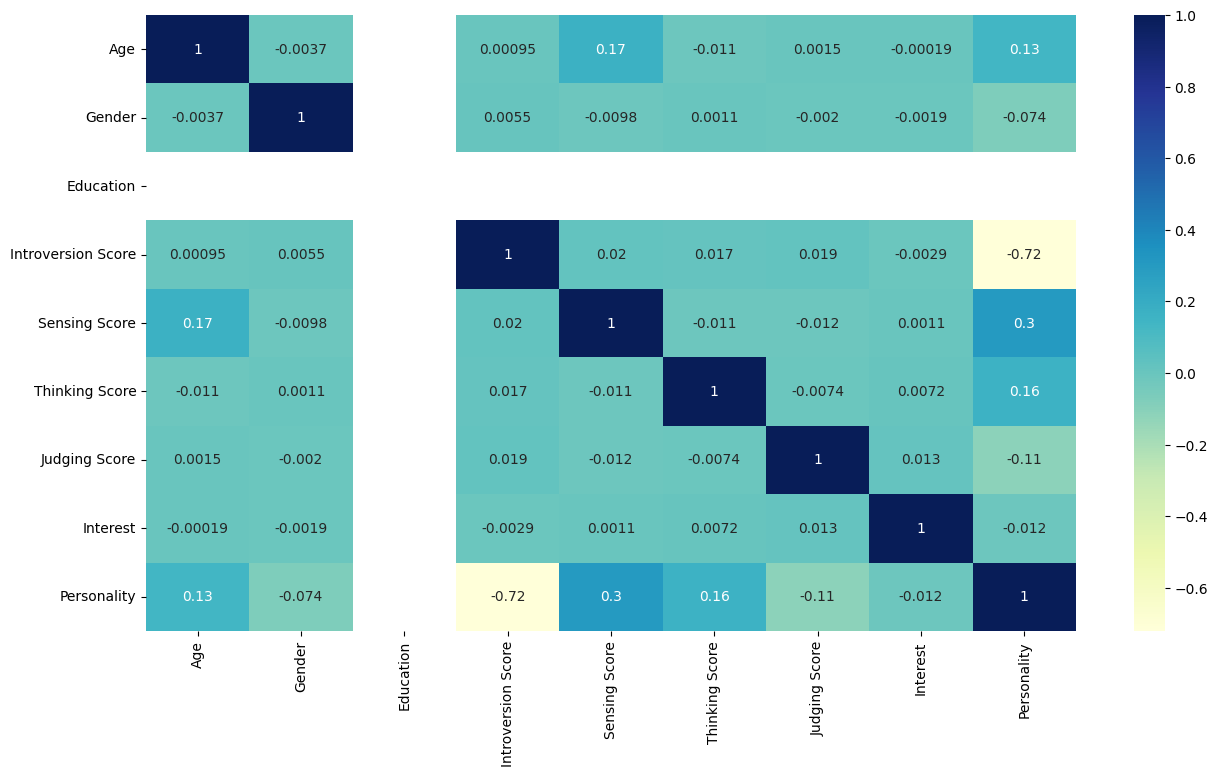

In [ ]:
plt.figure(figsize=(15, 8))
sns.heatmap(data.corr(), annot=True, cmap="YlGnBu")

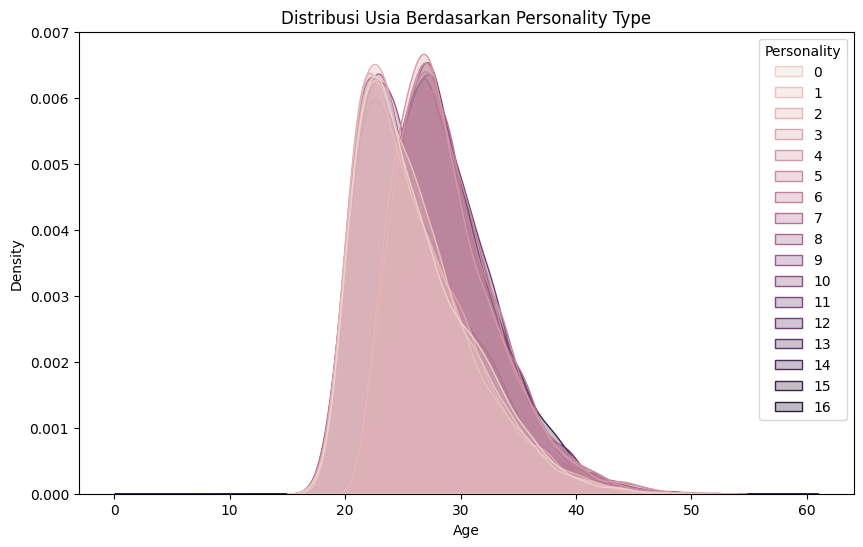

In [ ]:
plt.figure(figsize=(10,6))
sns.kdeplot(data=data, x="Age", hue="Personality", fill=True, alpha=0.3)
plt.title("Distribusi Usia Berdasarkan Personality Type")
plt.show()


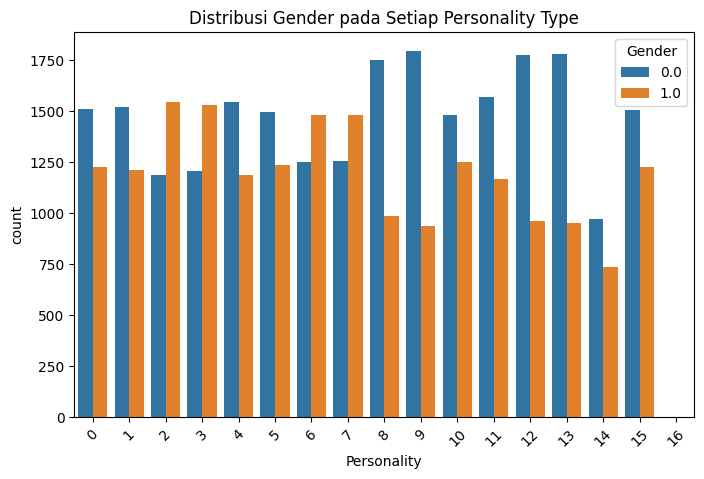

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(data=data, x="Personality", hue="Gender")
plt.xticks(rotation=45)
plt.title("Distribusi Gender pada Setiap Personality Type")
plt.show()


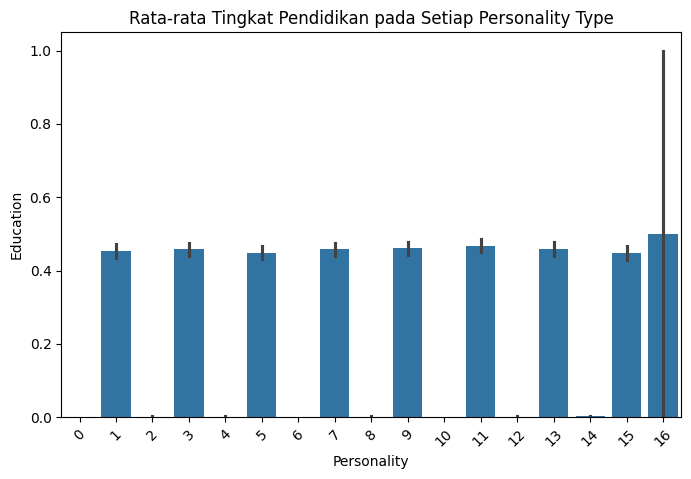

In [ ]:
plt.figure(figsize=(8,5))
sns.barplot(data=data, x="Personality", y="Education", estimator=lambda x: sum(x)/len(x))
plt.xticks(rotation=45)
plt.title("Rata-rata Tingkat Pendidikan pada Setiap Personality Type")
plt.show()


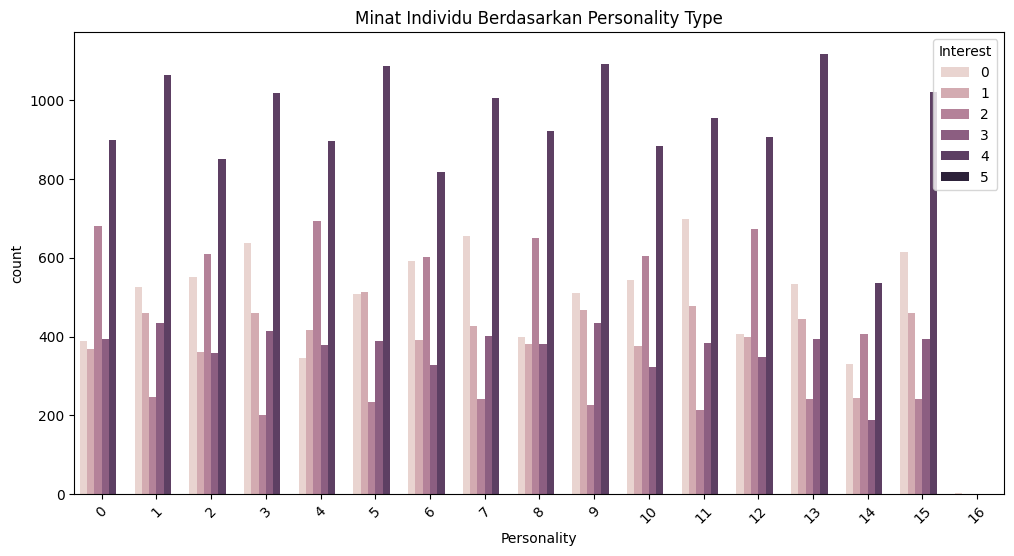

In [ ]:
plt.figure(figsize=(12,6))
sns.countplot(data=data, x="Personality", hue="Interest")
plt.xticks(rotation=45)
plt.title("Minat Individu Berdasarkan Personality Type")
plt.show()


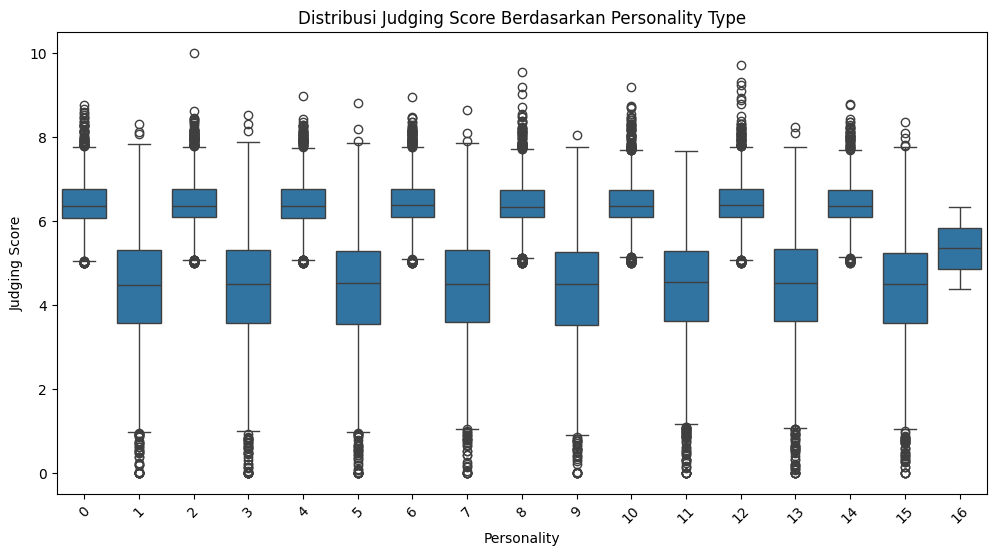

In [ ]:
plt.figure(figsize=(12,6))
sns.boxplot(data=data, x="Personality", y="Judging Score")
plt.xticks(rotation=45)
plt.title("Distribusi Judging Score Berdasarkan Personality Type")
plt.show()


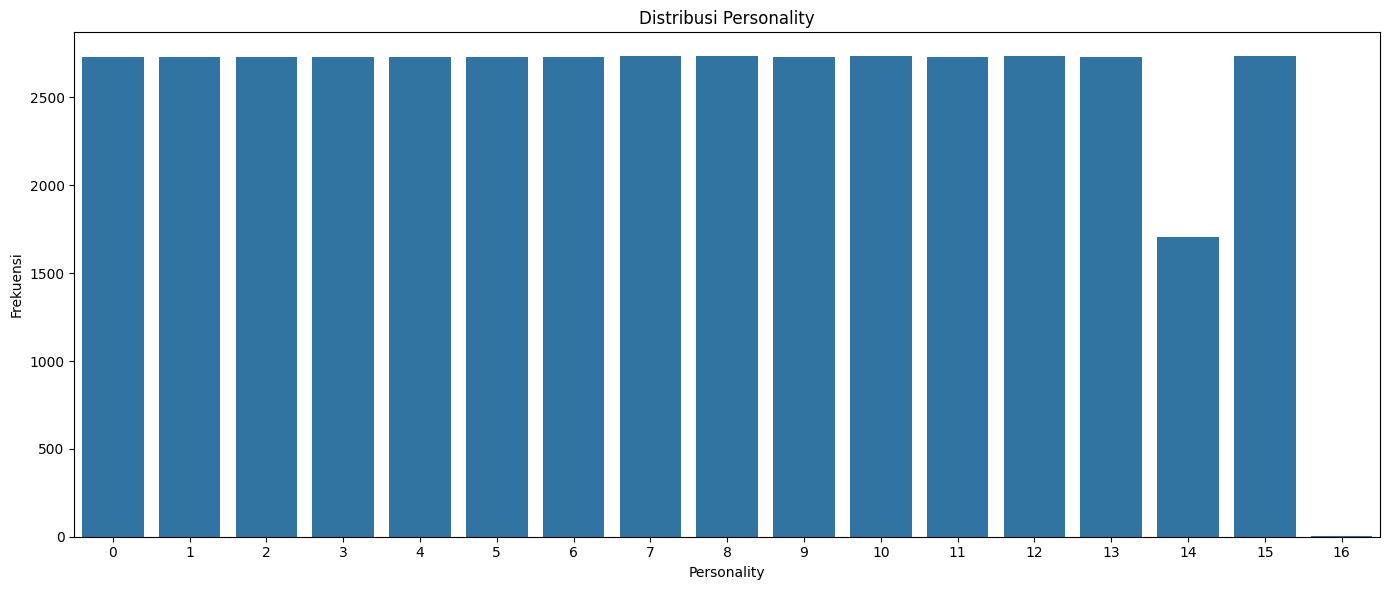

In [ ]:
plt.figure(figsize=(14, 6))
sns.countplot(x='Personality', data=data, order=sorted(data['Personality'].unique()))

plt.xticks(rotation=0)
plt.title("Distribusi Personality")
plt.xlabel("Personality")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

In [ ]:
Counter(data['Personality'])

Counter({3: 2733,
         11: 2733,
         5: 2732,
         0: 2733,
         13: 2732,
         12: 2734,
         6: 2733,
         9: 2733,
         7: 2734,
         1: 2732,
         10: 2734,
         4: 2732,
         14: 1706,
         8: 2734,
         15: 2734,
         2: 2732,
         16: 2})

In [ ]:
data.describe()

,Age,Gender,Education,Introversion Score,Sensing Score,Thinking Score,Judging Score,Interest,Personality
count,42703.000000,42703.000000,42703.000000,42703.000000,42703.000000,42703.000000,42703.000000,42703.000000,42703.000000
mean,27.400112,0.447510,0.234457,4.648361,5.757800,5.357804,5.366912,2.304007,7.344706
std,4.897014,0.497243,0.423664,2.903686,1.245534,2.901746,1.448091,1.545535,4.552233
min,18.000000,0.000000,0.000000,0.000150,0.000000,0.000320,0.000000,0.000000,0.000000
25%,24.000000,0.000000,0.000000,2.125760,4.921927,2.830165,4.480505,1.000000,3.000000
50%,27.000000,0.000000,0.000000,4.366050,6.146785,5.664130,5.724348,2.000000,7.000000
75%,30.000000,1.000000,0.000000,7.149590,6.611033,7.866380,6.397924,4.000000,11.000000
max,52.000000,1.000000,1.000000,9.999920,9.803837,9.999770,10.000000,5.000000,16.000000


array([[<Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Gender'}>,
        <Axes: title={'center': 'Education'}>],
       [<Axes: title={'center': 'Introversion Score'}>,
        <Axes: title={'center': 'Sensing Score'}>,
        <Axes: title={'center': 'Thinking Score'}>],
       [<Axes: title={'center': 'Judging Score'}>,
        <Axes: title={'center': 'Interest'}>,
        <Axes: title={'center': 'Personality'}>]], dtype=object)

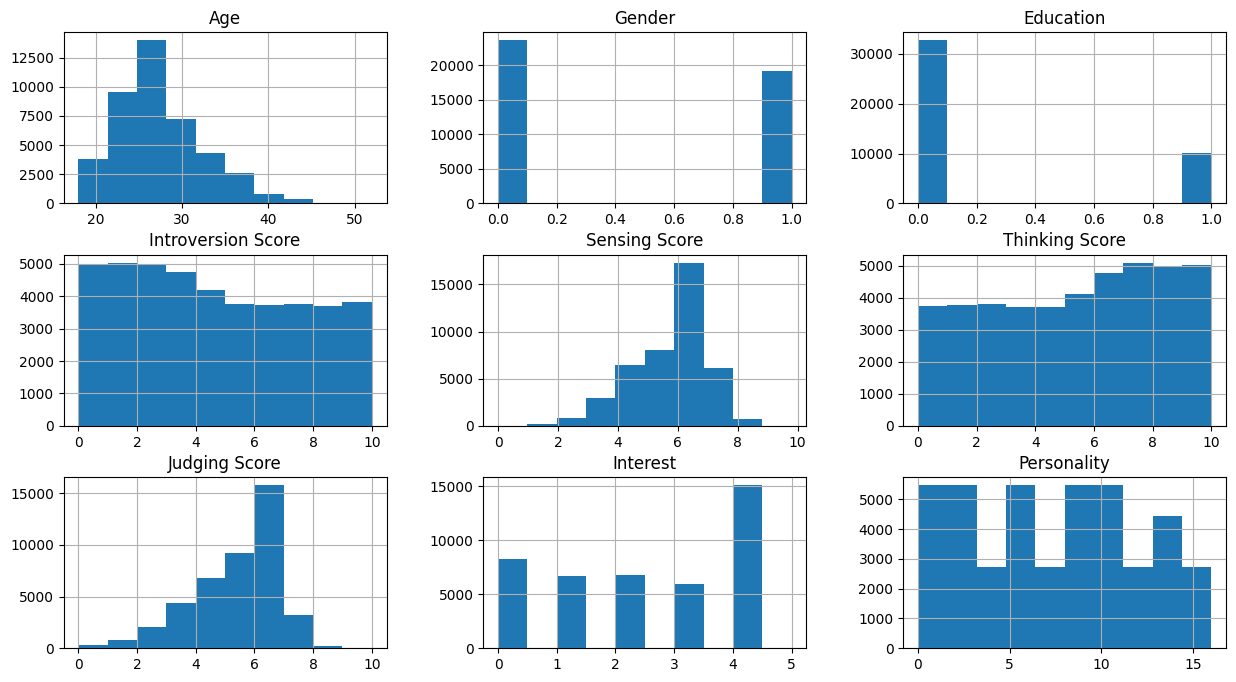

In [ ]:
data.hist(figsize=(15, 8))

In [ ]:
Counter(data['Personality'])

Counter({3: 2733,
         11: 2733,
         5: 2732,
         0: 2733,
         13: 2732,
         12: 2734,
         6: 2733,
         9: 2733,
         7: 2734,
         1: 2732,
         10: 2734,
         4: 2732,
         14: 1706,
         8: 2734,
         15: 2734,
         2: 2732,
         16: 2})

In [ ]:
X = data.drop('Personality', axis=1)
y = data['Personality']

In [ ]:
selector = SelectKBest(score_func=f_regression, k=5)
X_new = selector.fit_transform(X, y)

# Fitur terpilih
selected_features = X.columns[selector.get_support()]
print(selected_features)

Index(['Age', 'Introversion Score', 'Sensing Score', 'Thinking Score',
       'Judging Score'],
      dtype='object')


<Axes: >

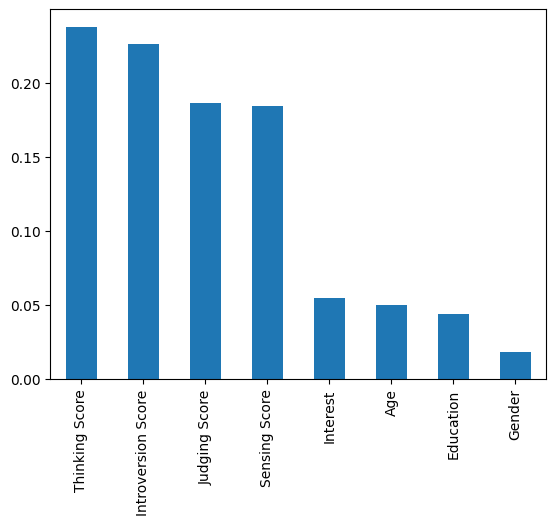

In [ ]:
model = RandomForestClassifier()
model.fit(X, y)

importances = model.feature_importances_

# Urutkan dan tampilkan
feature_importance = pd.Series(importances, index=X.columns)
feature_importance.sort_values(ascending=False).plot(kind='bar')

<Axes: >

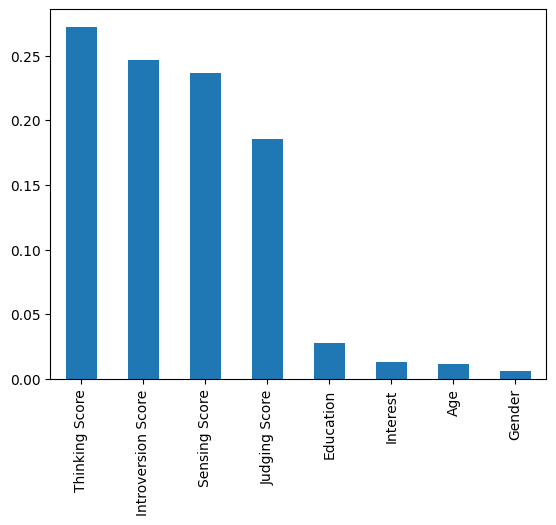

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

model = GradientBoostingClassifier()
model.fit(X, y)

importances = model.feature_importances_

feature_importance = pd.Series(importances, index=X.columns)
feature_importance.sort_values(ascending=False).plot(kind='bar')

<Axes: >

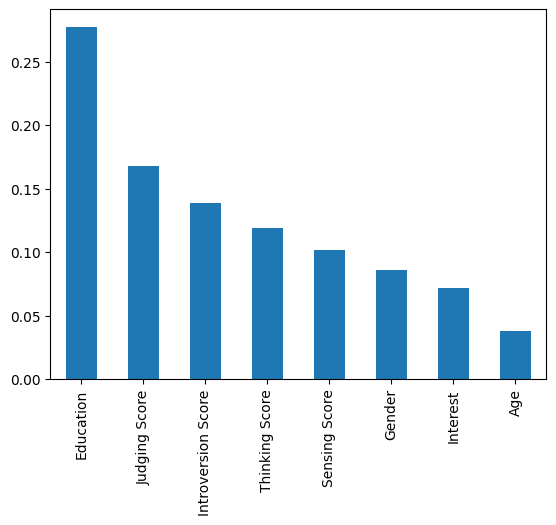

In [ ]:
from xgboost import XGBClassifier

model = XGBClassifier()
model.fit(X, y)

importances = model.feature_importances_

feature_importance = pd.Series(importances, index=X.columns)
feature_importance.sort_values(ascending=False).plot(kind='bar')

In [ ]:
Counter(y)

Counter({3: 2733,
         11: 2733,
         5: 2732,
         0: 2733,
         13: 2732,
         12: 2734,
         6: 2733,
         9: 2733,
         7: 2734,
         1: 2732,
         10: 2734,
         4: 2732,
         14: 1706,
         8: 2734,
         15: 2734,
         2: 2732,
         16: 2})

In [ ]:
Counter(data['Personality'])

Counter({3: 2733,
         11: 2733,
         5: 2732,
         0: 2733,
         13: 2732,
         12: 2734,
         6: 2733,
         9: 2733,
         7: 2734,
         1: 2732,
         10: 2734,
         4: 2732,
         14: 1706,
         8: 2734,
         15: 2734,
         2: 2732,
         16: 2})

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
X_scaled

array([[-1.30695722,  1.1111207 ,  1.8069814 , ...,  0.67747106,
         0.06582002, -1.49076747],
       [-0.69433178,  1.1111207 ,  1.8069814 , ...,  0.93426085,
        -1.10622811,  1.09736292],
       [-0.28591482,  1.1111207 ,  1.8069814 , ..., -0.41116562,
         0.06044556, -0.84373487],
       ...,
       [ 0.32671061, -0.89999223, -0.55340913, ..., -1.75848407,
        -1.20382983,  1.09736292],
       [-0.89854026, -0.89999223, -0.55340913, ..., -1.01357208,
        -0.49230656, -1.49076747],
       [-1.30695722, -0.89999223, -0.55340913, ..., -1.06868782,
         0.42112909,  1.09736292]])

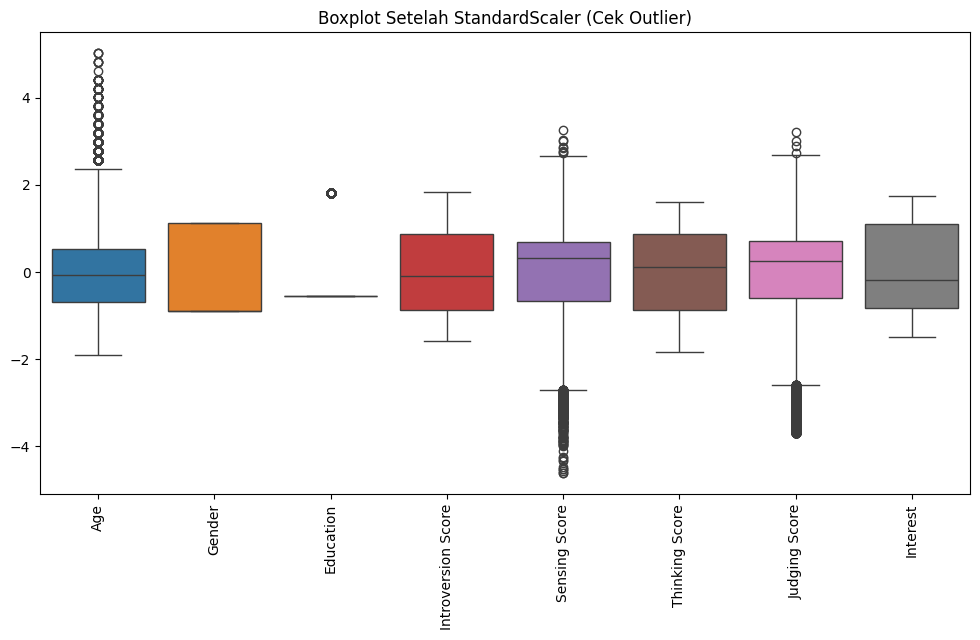

In [ ]:
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

plt.figure(figsize=(12, 6))
sns.boxplot(data=X_scaled_df)
plt.xticks(rotation=90)
plt.title("Boxplot Setelah StandardScaler (Cek Outlier)")
plt.show()

In [ ]:
scalerminmax = MinMaxScaler()
X_scaled_minmax = scalerminmax.fit_transform(X)

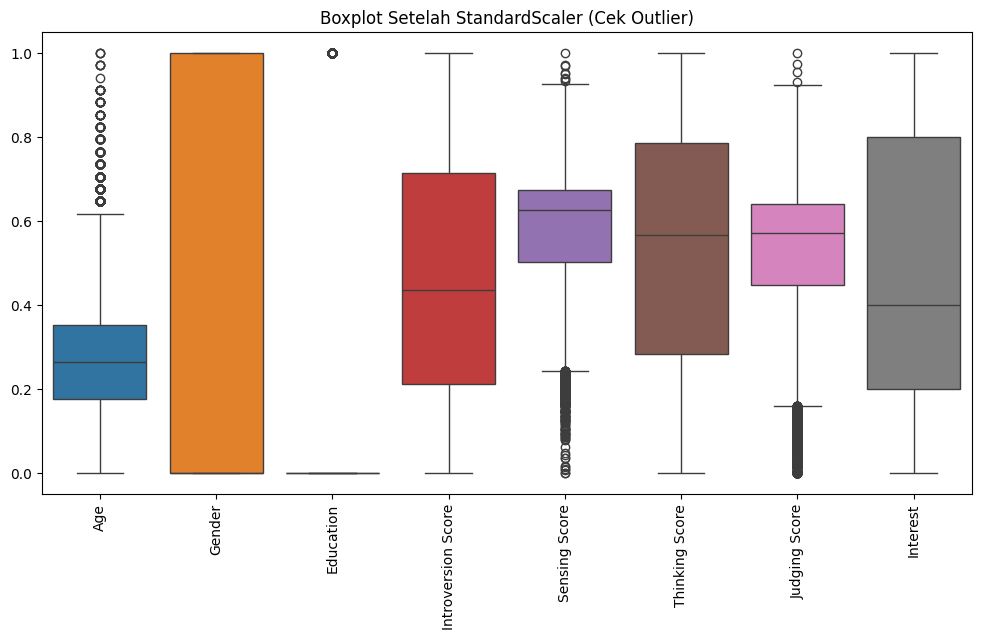

In [ ]:
X_scaled_minmax = pd.DataFrame(X_scaled_minmax, columns=X.columns)

plt.figure(figsize=(12, 6))
sns.boxplot(data=X_scaled_minmax)
plt.xticks(rotation=90)
plt.title("Boxplot Setelah StandardScaler (Cek Outlier)")
plt.show()

In [ ]:
scaler_robust = RobustScaler()
X_scaled_robust = scaler_robust.fit_transform(X)

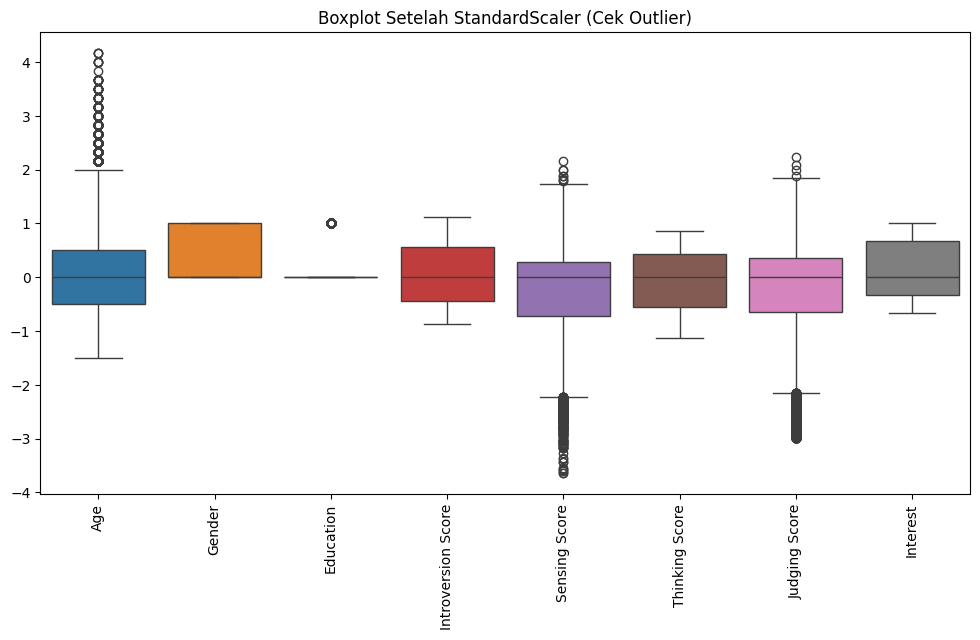

In [ ]:
X_scaled_robust = pd.DataFrame(X_scaled_robust, columns=X.columns)

plt.figure(figsize=(12, 6))
sns.boxplot(data=X_scaled_robust)
plt.xticks(rotation=90)
plt.title("Boxplot Setelah StandardScaler (Cek Outlier)")
plt.show()

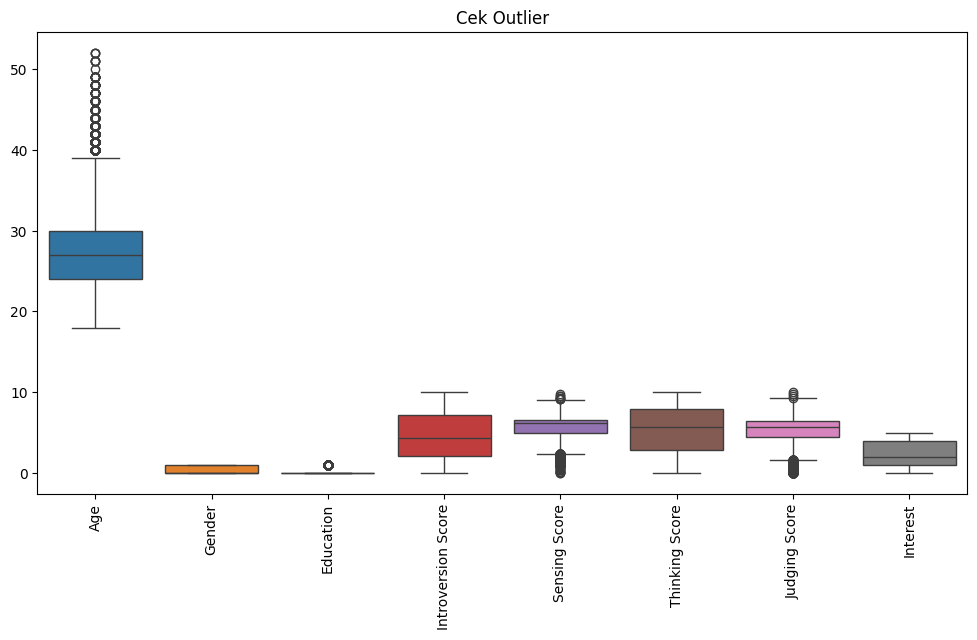

In [ ]:
# Plot semua fitur
plt.figure(figsize=(12, 6))
sns.boxplot(data=X)
plt.xticks(rotation=90)
plt.title("Cek Outlier")
plt.show()

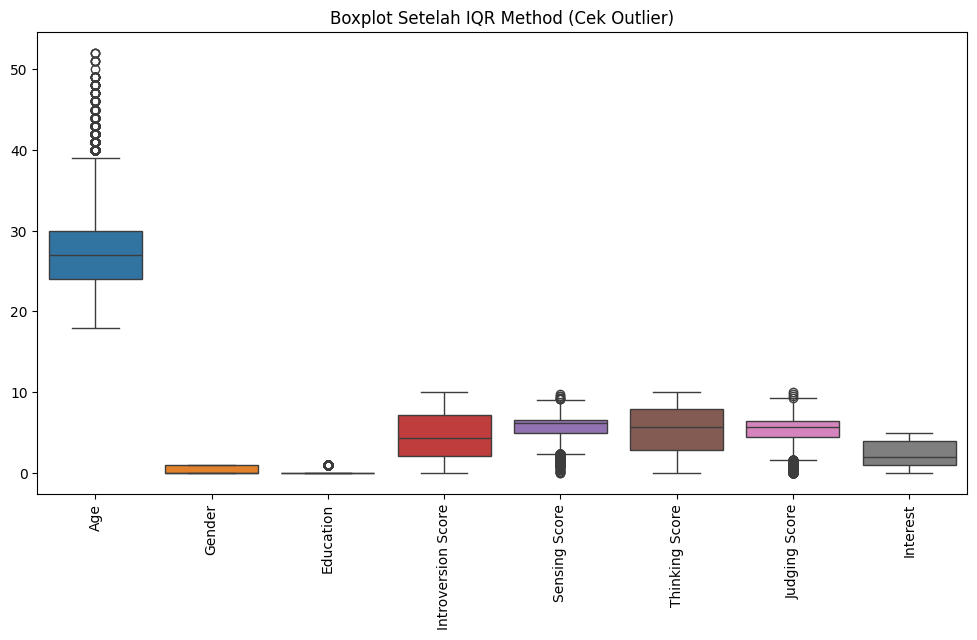

In [ ]:
# Plot semua fitur
plt.figure(figsize=(12, 6))
sns.boxplot(data=X)
plt.xticks(rotation=90)
plt.title("Boxplot Setelah IQR Method (Cek Outlier)")
plt.show()

In [ ]:
# Misal X adalah DataFrame
Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1

# Batas bawah dan atas
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Cek apakah nilai di luar batas
outliers = ((data < lower_bound) | (data > upper_bound))

# Hitung jumlah outlier per kolom
outliers.sum()

,0
Age,840
Gender,0
Education,10009
Introversion Score,0
Sensing Score,422
Thinking Score,0
Judging Score,684
Interest,0
Personality,0


In [ ]:
data = data[~((data < lower_bound) | (data > upper_bound)).any(axis=1)]

In [ ]:
X = data.drop(['Personality'], axis=1)
y = data['Personality']

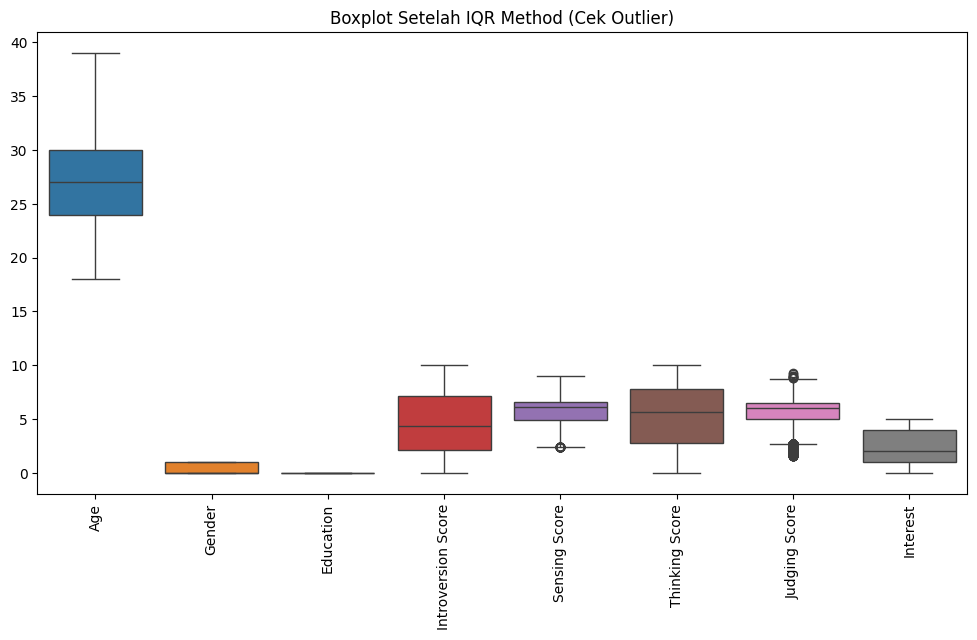

In [ ]:
# Plot semua fitur
plt.figure(figsize=(12, 6))
sns.boxplot(data=X)
plt.xticks(rotation=90)
plt.title("Boxplot Setelah IQR Method (Cek Outlier)")
plt.show()

In [ ]:
Counter(y)

Counter({0: 2644,
         13: 1402,
         12: 2665,
         6: 2664,
         1: 1387,
         10: 2644,
         7: 1394,
         4: 2658,
         14: 1658,
         8: 2637,
         15: 1423,
         2: 2642,
         9: 1373,
         5: 1408,
         3: 1391,
         11: 1351,
         16: 1})

In [ ]:
ros = RandomOverSampler()
X_resampled, y_resampled = ros.fit_resample(X, y)

In [ ]:
Counter(y_resampled)

Counter({0: 2665,
         13: 2665,
         12: 2665,
         6: 2665,
         1: 2665,
         10: 2665,
         7: 2665,
         4: 2665,
         14: 2665,
         8: 2665,
         15: 2665,
         2: 2665,
         9: 2665,
         5: 2665,
         3: 2665,
         11: 2665,
         16: 2665})

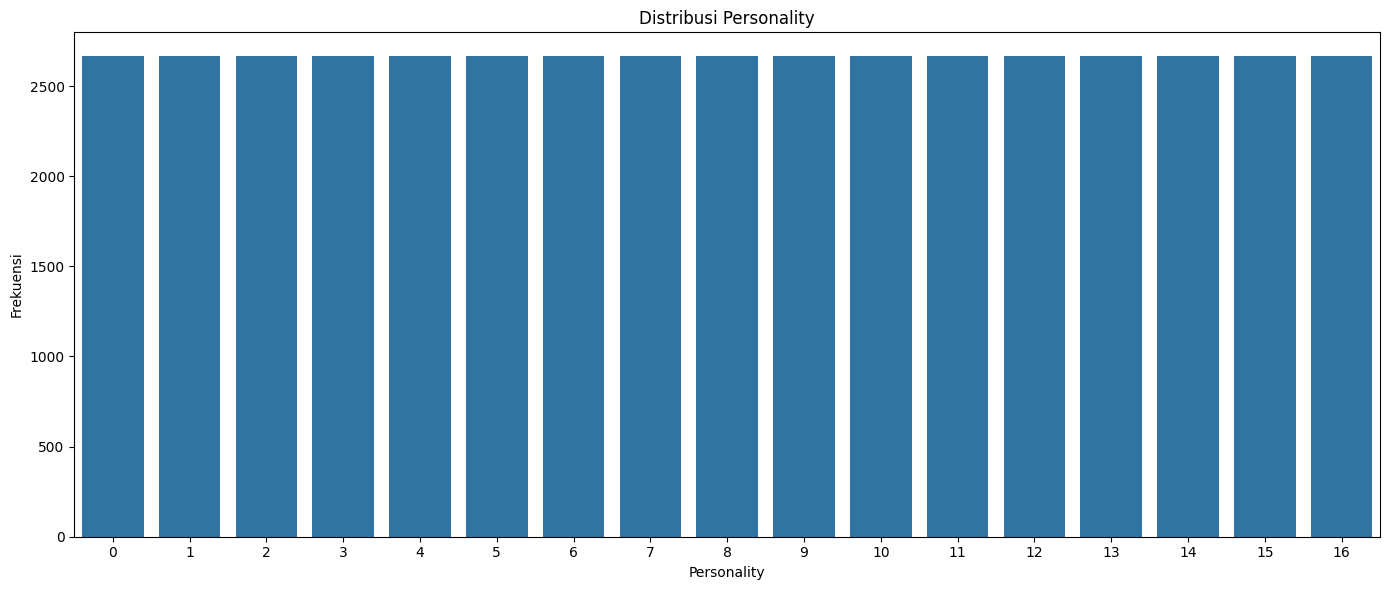

In [ ]:
plt.figure(figsize=(14, 6))
sns.countplot(x=y_resampled, order=sorted(y.unique()))

plt.xticks(rotation=0)
plt.title("Distribusi Personality")
plt.xlabel("Personality")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

# Pemodelan

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.2, random_state=42)

In [ ]:
model = RandomForestClassifier()
model.fit(X_train, y_train)

RandomForestClassifier()

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
y_probs = model.predict_proba(X_test)

In [ ]:
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc}")

Accuracy: 0.9438251848581835


In [ ]:
# Menghitung metrik
f1 = f1_score(y_test, y_pred, average='weighted')
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
roc_auc = roc_auc_score(y_test, y_probs, multi_class='ovr')

print("F1 Score     :", f1)
print("Precision    :", precision)
print("Recall       :", recall)
print("ROC AUC Score:", roc_auc)

F1 Score     : 0.9437711232281283
Precision    : 0.9442428747221541
Recall       : 0.9438251848581835
ROC AUC Score: 0.9986197634533075


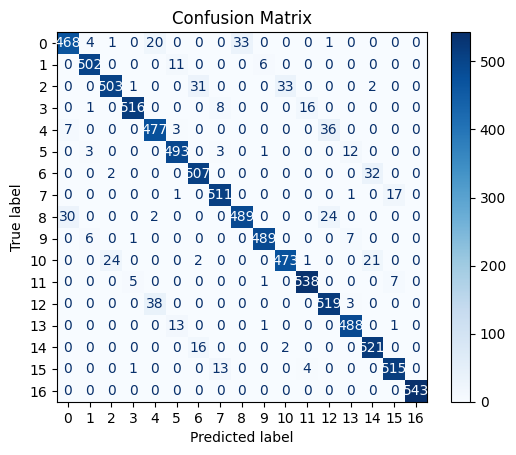

In [ ]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.grid(False)
plt.show()

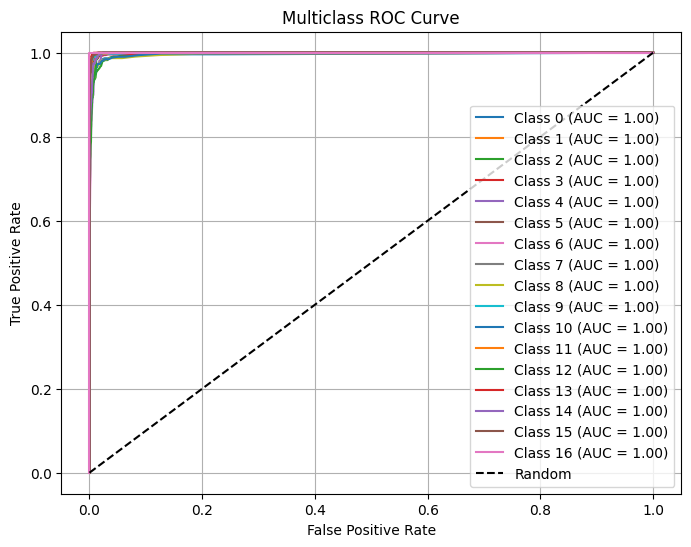

In [ ]:
# Misal jumlah kelas:
classes = np.unique(y)
n_classes = len(classes)

# Konversi y_test jadi one-hot (binarize)
y_test_bin = label_binarize(y_test, classes=classes)

# ROC Curve untuk setiap kelas
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot semua ROC Curve
plt.figure(figsize=(8, 6))
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label=f"Class {classes[i]} (AUC = {roc_auc[i]:.2f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass ROC Curve')
plt.legend(loc='lower right')
plt.grid()
plt.show()

In [ ]:
# Data baru dalam bentuk list atau array
new_data = {
    'Age': [22, 24],
    'Gender': ['Female', 'Male'],
    'Education': [1, 0],
    'Introversion Score': [5.5, 6.2],
    'Sensing Score': [8.5, 4.0],
    'Thinking Score': [3.0, 6.5],
    'Judging Score': [1.0, 6.7],
    'Interest': ['Arts', 'Sports']
}

# Ubah menjadi DataFrame
df_new = pd.DataFrame(new_data)

# Jika perlu, lakukan preprocessing (misalnya encoding kolom kategorikal 'Gender')
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df_new['Gender'] = le.fit_transform(df_new['Gender'])
df_new['Interest'] = le.fit_transform(df_new['Interest'])

In [ ]:
# Lakukan prediksi
predictions = model.predict(df_new)

# Tampilkan hasil prediksi
print(predictions)

[5 2]


# Another Method

In [ ]:
models = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric='mlogloss')
}

In [ ]:
results = {}

for name, model in models.items():
    print(f"--- Melatih Model: {name} ---")
    # Melatih model
    model.fit(X_train, y_train)

    # Melakukan prediksi
    y_pred = model.predict(X_test)

    # Evaluasi performa
    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')

    results[name] = {
        "Accuracy": accuracy,
        "F1 Score": f1,
        "Precision": precision,
        "Recall": recall
    }

    print(f"Accuracy: {accuracy:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print("-" * 30)

--- Melatih Model: Random Forest ---
Accuracy: 0.9459
F1 Score: 0.9459
Precision: 0.9463
Recall: 0.9459
------------------------------
--- Melatih Model: Gradient Boosting ---
Accuracy: 0.9186
F1 Score: 0.9187
Precision: 0.9197
Recall: 0.9186
------------------------------
--- Melatih Model: XGBoost ---


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [13:40:29] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Accuracy: 0.9371
F1 Score: 0.9371
Precision: 0.9376
Recall: 0.9371
------------------------------


                   Accuracy  F1 Score  Precision    Recall
Random Forest      0.945922  0.945872   0.946339  0.945922
Gradient Boosting  0.918552  0.918651   0.919663  0.918552
XGBoost            0.937093  0.937087   0.937612  0.937093


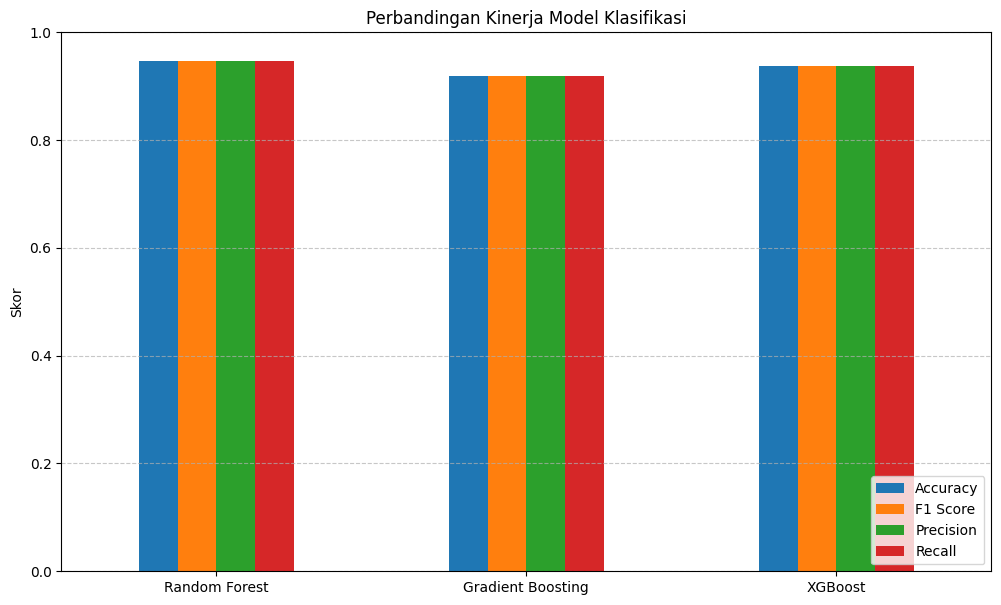

In [ ]:
results_df = pd.DataFrame(results).T
print(results_df)

# Visualisasi perbandingan
results_df.plot(kind='bar', figsize=(12, 7))
plt.title("Perbandingan Kinerja Model Klasifikasi")
plt.ylabel("Skor")
plt.xticks(rotation=0)
plt.ylim(0, 1.0)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()